<a href="https://colab.research.google.com/github/madhavharshit/UCS420/blob/main/Assignment_7_Harshit_Pachauri.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [2]:
ROLL_NO = int(input("Enter your RollNo."))
NAME = input("Enter your Name").strip()

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

Enter your RollNo.1024160051
Enter your NameHarshit Madhav Pachauri


### Dataset generator — do not modify

In [3]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [4]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160051   Name: Harshit Madhav Pachauri   Fingerprint: 50D47D10   Tickets: 13

Ticket_ID                                                                               Ticket_Text
      T01 I was locked out of the printer when I use mobile hotspot. The same problem occurs again.
      T02                                                    Only 2 of 30 PCs boot after 3.5 hours.
      T03                                       The VPN keeps asking for login. Can you check this?
      T04                                                        Dr. Rao's lab PC (No. 14) is down.
      T05                Email is not working when I use mobile hotspot. Is there another solution?
      T06                        WiFi was working yesterday when I use mobile hotspot. Please help.
      T07                                                               My roll no. is 1023-03-021.
      T08                                       I reinstalled the VPN since yesterday. Please help.
     

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [7]:
import string
import re

records = []
processed = {}
for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    processed[row["Ticket_ID"]] = result
    records.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique tokens": len(set(result["tokens"])),
        "Final tokens": len(result["final"])
    })

summary = pd.DataFrame(records)
total = {"Ticket_ID": "TOTAL"}
for col in ["Sentences", "Tokens", "Punctuation", "Stopwords", "Final tokens"]:
    total[col] = int(summary[col].sum())
total["Unique tokens"] = int(len(set(t for item in processed.values() for t in item["tokens"])))
summary = pd.concat([summary, pd.DataFrame([total])], ignore_index=True)
display(summary)

selected_id = FOCUS[0]
selected = processed[selected_id]
print("Selected ticket:", selected_id)
print(df.loc[df["Ticket_ID"] == selected_id, "Ticket_Text"].iloc[0])
print("Tokens:", selected["tokens"])
print("Punctuation tokens:", selected["punct"])
print("Stopwords:", selected["stops"])
print("Final tokens:", selected["final"])

nonword_tokens = sorted({t for item in processed.values() for t in item["final"]
                         if not re.search(r"[a-z]", t) or t in {"n't", "'s", "ca", "wo"}})
print("\nObservation: Some final tokens may be fragments such as n't, 's, ca or wo. They come from word_tokenize splitting contractions; punctuation and stopwords are removed separately.")

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique tokens,Final tokens
0,T01,2,19,2,10,16,7
1,T02,1,10,1,3,10,6
2,T03,2,12,2,5,12,5
3,T04,2,13,4,3,12,6
4,T05,2,15,2,6,14,7
5,T06,2,13,2,3,12,8
6,T07,2,7,2,3,6,2
7,T08,2,10,2,2,9,6
8,T09,2,17,2,8,17,7
9,T10,2,14,2,6,13,6


Selected ticket: T04
Dr. Rao's lab PC (No. 14) is down.
Tokens: ['dr.', 'rao', "'s", 'lab', 'pc', '(', 'no', '.', '14', ')', 'is', 'down', '.']
Punctuation tokens: ['(', '.', ')', '.']
Stopwords: ['no', 'is', 'down']
Final tokens: ['dr.', 'rao', "'s", 'lab', 'pc', '14']

Observation: Some final tokens may be fragments such as n't, 's, ca or wo. They come from word_tokenize splitting contractions; punctuation and stopwords are removed separately.


**Observation:** Final tokens such as `n't`, `'s`, `ca` or `wo` may remain because NLTK's `word_tokenize()` splits contractions and the official pipeline only removes punctuation and stopwords.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [9]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

raw_tickets = df["Ticket_Text"].tolist()
all_raw_text = "\n".join(raw_tickets)

patterns = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",
    "Numbers": r"(?<![A-Za-z])\d+(?:\.\d+)*(?![A-Za-z])",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words beginning with a vowel": r"\b[AEIOUaeiou][A-Za-z]*\b"
}

for label, pattern in patterns.items():
    print(f"\n{label} (tickets):")
    print(re.findall(pattern, all_raw_text))

email_pattern = r"\b[A-Za-z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+\b"
url_pattern = r"(?:https?://|www\.)[^\s<>]+"
phone_pattern = r"(?<!\w)(?:\+\d{1,3}[ -]?)?(?:\(?\d{3,5}\)?[ -]?)\d{3,5}[ -]\d{3,5}(?!\w)"

def redact(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, lambda m: m.group(0).rstrip(".,;:!?") and "<URL>" + m.group(0)[len(m.group(0).rstrip(".,;:!?")):], text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("\nRegex extraction on TEST_LINES:")
for line in TEST_LINES:
    print("\n", line)
    for label, pattern in patterns.items():
        print(label + ":", re.findall(pattern, line))
    print("Redacted:", redact(line))

capitalized = re.findall(patterns["Capitalized words"], all_raw_text)
sentence_initial = 0
for ticket in raw_tickets:
    for match in re.finditer(r"(?:^|[.!?]\s+)([A-Z][a-zA-Z]*)", ticket):
        sentence_initial += 1
print("\nCapitalized words across tickets:", len(capitalized))
print("Words capitalized because they start a sentence (estimated):", sentence_initial)
print("Observation: Capitalized-word extraction also captures names, acronyms and product names; sentence-initial capitalization is one source of matches.")


Words longer than 5 letters (tickets):
['locked', 'printer', 'mobile', 'hotspot', 'problem', 'occurs', 'asking', 'working', 'mobile', 'hotspot', 'another', 'solution', 'working', 'yesterday', 'mobile', 'hotspot', 'Please', 'reinstalled', 'yesterday', 'Please', 'cannot', 'access', 'Python', 'connected', 'campus', 'another', 'solution', 'Server', 'stopped', 'syncing', 'laptop', 'problem', 'occurs', 'printer', 'stopped', 'syncing', 'urgent', 'Nothing', 'nobody', 'replied', 'locked', 'Matlab', 'during']

Numbers (tickets):
['2', '30', '3.5', '14', '1023', '03', '021']

Capitalized words (tickets):
['I', 'I', 'The', 'Only', 'PCs', 'The', 'VPN', 'Can', 'Dr', 'Rao', 'PC', 'No', 'Email', 'I', 'Is', 'WiFi', 'I', 'Please', 'My', 'I', 'VPN', 'Please', 'I', 'Python', 'Wi', 'Fi', 'Is', 'Server', 'The', 'The', 'This', 'Nothing', 'I', 'Matlab', 'Can']

Words beginning with a vowel (tickets):
['I', 'out', 'of', 'I', 'use', 'occurs', 'again', 'Only', 'of', 'after', 'asking', 'is', 'Email', 'is', 'I', 

**Observation:** The code above estimates sentence-initial capitalized words and prints the result. Other capitalized matches can include names, acronyms and product names.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [10]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

token_pattern = r"""https?://[^\s<>]+|www\.[^\s<>]+|[A-Za-z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+|\+?\d[\d(). -]{5,}\d|\d+(?:\.\d+)+|[A-Za-z]+(?:['’][A-Za-z]+)+(?:-[A-Za-z]+(?:['’][A-Za-z]+)*)*|[A-Za-z0-9]+(?:-[A-Za-z0-9]+)+|[A-Za-z]+|[^\w\s]"""
regexp_tokenizer = RegexpTokenizer(token_pattern)

def my_tokenize(text):
    return regexp_tokenizer.tokenize(text)

print("TEST_LINES comparison:")
for i, line in enumerate(TEST_LINES, start=1):
    print(f"\\nLine {i}: {line}")
    print("my_tokenize:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

comparison = []
for _, row in df.iterrows():
    custom = my_tokenize(row["Ticket_Text"])
    standard = word_tokenize(row["Ticket_Text"])
    comparison.append({
        "Ticket_ID": row["Ticket_ID"],
        "Custom count": len(custom),
        "word_tokenize count": len(standard),
        "Different": custom != standard
    })
comparison_df = pd.DataFrame(comparison)
display(comparison_df)
different_count = int(comparison_df["Different"].sum())
print(f"Tickets with different token lists: {different_count} out of {len(df)}")
print("Examples of differences: the custom tokenizer keeps Wi-Fi/state-of-the-art and contractions as single tokens, and keeps URLs, emails, phone numbers, decimals and versions together. word_tokenize generally splits several of these into multiple tokens.")

TEST_LINES comparison:
\nLine 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
\nLine 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', ',', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
\nLine 3: The state-of-the-art lab isn't open; log-in at 5.30 p.m.

,Ticket_ID,Custom count,word_tokenize count,Different
0,T01,19,19,False
1,T02,8,10,True
2,T03,12,12,False
3,T04,12,13,True
4,T05,15,15,False
5,T06,13,13,False
6,T07,7,7,False
7,T08,10,10,False
8,T09,16,17,True
9,T10,14,14,False


Tickets with different token lists: 3 out of 13
Examples of differences: the custom tokenizer keeps Wi-Fi/state-of-the-art and contractions as single tokens, and keeps URLs, emails, phone numbers, decimals and versions together. word_tokenize generally splits several of these into multiple tokens.


**Observation:** The code above counts tickets whose custom token lists differ from `word_tokenize()`.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [13]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
import pandas as pd

# Extract unique final tokens across all processed tickets
final_unique = sorted(set(token for item in processed.values() for token in item["final"]))

# Initialize stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()
# Custom suffix stemmer, e.g., stemming suffix 'ing' or 's'
regexp = RegexpStemmer('ing$|s$|ed$', min=4)
lemmatizer = WordNetLemmatizer()

# Helper function to map POS tags to WordNet tags
def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return 'a'
    elif treebank_tag.startswith('V'):
        return 'v'
    elif treebank_tag.startswith('N'):
        return 'n'
    elif treebank_tag.startswith('R'):
        return 'r'
    else:
        return 'n'  # Default to noun

# POS Tagging the unique final tokens
pos_tagged = pos_tag(final_unique)

comparison_records = []
for word, tag in pos_tagged:
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regexp.stem(word)

    wn_pos = get_wordnet_pos(tag)
    lemmed = lemmatizer.lemmatize(word, pos=wn_pos)

    # Only keep records where at least one output differs
    if len({word, p_stem, l_stem, r_stem, lemmed}) > 1:
        comparison_records.append({
            "Word": word,
            "POS Tag": tag,
            "Porter": p_stem,
            "Lancaster": l_stem,
            "RegexpStemmer": r_stem,
            "Lemmatizer": lemmed
        })

comparison_df = pd.DataFrame(comparison_records)
display(comparison_df)
print(f"Number of words with differences: {len(comparison_df)} out of {len(final_unique)}")

,Word,POS Tag,Porter,Lancaster,RegexpStemmer,Lemmatizer
0,access,NN,access,access,acces,access
1,another,DT,anoth,anoth,another,another
2,asking,VBG,ask,ask,ask,ask
3,campus,NN,campu,camp,campu,campus
4,connected,VBD,connect,connect,connect,connect
5,hours,NNS,hour,hour,hour,hour
6,keeps,VBZ,keep,keep,keep,keep
7,locked,VBN,lock,lock,lock,lock
8,mobile,IN,mobil,mobl,mobile,mobile
9,nobody,NN,nobodi,nobody,nobody,nobody


Number of words with differences: 29 out of 51


**Observation:** Compare the displayed table for examples of over-stemming (different words reduced too aggressively) and under-stemming (related forms left apart). Results depend on the generated tickets.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total tokens,Unique tokens,TTR
0,S1: all tokens,163,80,0.4908
1,S2: no punctuation,137,76,0.5547
2,S3: final tokens,72,51,0.7083
3,S4: Porter stemmed S3,72,49,0.6806


Top 10 words in S1: [('.', 20), ('the', 9), ('i', 7), ('is', 6), ('when', 4), ('?', 4), ('was', 3), ('of', 3), ('use', 3), ('mobile', 3)]
Top 10 words in S3: [('use', 3), ('mobile', 3), ('hotspot', 3), ('locked', 2), ('printer', 2), ('problem', 2), ('occurs', 2), ('vpn', 2), ('check', 2), ('lab', 2)]
Top 5 bigrams in S1: [(('.', 'the'), 4), (('when', 'i'), 3), (('i', 'use'), 3), (('use', 'mobile'), 3), (('mobile', 'hotspot'), 3)]
Top 5 bigrams in S3: [(('use', 'mobile'), 3), (('mobile', 'hotspot'), 3), (('problem', 'occurs'), 2), (('another', 'solution'), 2), (('please', 'help'), 2)]


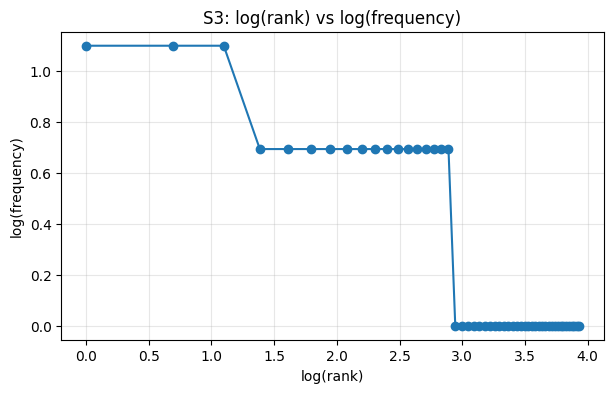

Observation: TTR changes because removing punctuation and stopwords reduces the token count, while stemming merges related word forms and can reduce the number of unique tokens. The exact values depend on the roll-number-generated dataset.


In [14]:
from collections import Counter
from nltk.util import ngrams
import numpy as np
import matplotlib.pyplot as plt

S1 = [token.lower() for item in processed.values() for token in item["tokens"]]
S2 = [token for token in S1 if not is_punct(token)]
S3 = [token for item in processed.values() for token in item["final"]]
S4 = [porter.stem(token) for token in S3]

def corpus_row(name, seq):
    return {"Corpus": name, "Total tokens": len(seq), "Unique tokens": len(set(seq)),
            "TTR": round(len(set(seq)) / len(seq), 4) if seq else 0}

stats = pd.DataFrame([
    corpus_row("S1: all tokens", S1),
    corpus_row("S2: no punctuation", S2),
    corpus_row("S3: final tokens", S3),
    corpus_row("S4: Porter stemmed S3", S4)
])
display(stats)

print("Top 10 words in S1:", Counter(S1).most_common(10))
print("Top 10 words in S3:", Counter(S3).most_common(10))
print("Top 5 bigrams in S1:", Counter(ngrams(S1, 2)).most_common(5))
print("Top 5 bigrams in S3:", Counter(ngrams(S3, 2)).most_common(5))

frequencies = Counter(S3).most_common()
if frequencies:
    ranks = np.arange(1, len(frequencies) + 1)
    freqs = np.array([freq for _, freq in frequencies])
    plt.figure(figsize=(7, 4))
    plt.plot(np.log(ranks), np.log(freqs), marker="o", linestyle="-")
    plt.xlabel("log(rank)")
    plt.ylabel("log(frequency)")
    plt.title("S3: log(rank) vs log(frequency)")
    plt.grid(True, alpha=0.3)
    plt.show()

print("Observation: TTR changes because removing punctuation and stopwords reduces the token count, while stemming merges related word forms and can reduce the number of unique tokens. The exact values depend on the roll-number-generated dataset.")

**Observation:** TTR changes because punctuation and stopwords are removed between S1 and S3, and Porter stemming can merge different word forms in S4. The exact values depend on your generated dataset.